NOME: Márcio Guilherme Ventola Pereira

# Trabalho prático — comparação de três modelos em seis datasets

**Atividade de aprendizado de máquina — Engenharia de Software**

Este notebook usa **seis datasets reais** para comparar três algoritmos de classificação: Decision Tree, Random Forest e Gradient Boosting. O objetivo é verificar qual funciona melhor em cada conjunto de dados.

Para todos os seis datasets, separo **80% para treino e 20% para teste**, com `random_state=42`. Uso validação cruzada de **cinco partes apenas nos dados de treino**. Escolho o melhor modelo pelo **F1 médio na validação**, e depois apresento o desempenho dos três modelos na parte de teste.

As tabelas e figuras a seguir são **resultados reais calculados ao executar o notebook**, sem criar registros fictícios. Os seis arquivos estão incluídos na pasta `dados/` do projeto.


## Quais datasets foram usados?

| Dataset | O que o modelo tenta prever |
|---|---|
| 1. Student Stress Factors | O nível de estresse do estudante (0, 1 ou 2) |
| 2. Heart Disease | Se há ou não indicação de doença cardíaca |
| 3. FISHMORPH | Se o peixe pertence à ordem Cypriniformes (sim/não) |
| 4. Eleição americana — Literary Digest 1936 | Se Landon obteve pelo menos 40% dos votos dos dois principais candidatos em cada estado |
| 5. Breast Cancer Wisconsin | Diagnóstico: benigno (0) ou maligno (1) |
| 6. Red Wine Quality | Qualidade do vinho: nota menor que 6 (0) ou igual/maior que 6 (1) |

**Observação sobre a eleição:** a atividade anterior usava regressão para corrigir o viés da pesquisa. Aqui a tarefa é classificação. Por isso, usei a porcentagem de 40% como critério para formar duas classes, já que apenas dois estados elegeram Landon e seria inviável usar cinco divisões estratificadas para prever diretamente os vencedores. Esse limite é uma escolha do exercício e **não corresponde a quem venceu a eleição**.

**Observação sobre FISHMORPH:** como a tabela contém muitas ordens de peixes, transformei a tarefa em "Cypriniformes ou não". A classificação é feita com medidas do corpo, e não com nomes de espécies, gêneros ou famílias.


## 1. Importando as bibliotecas

Usei as bibliotecas básicas presentes no material anterior (`pandas`, `numpy`, `matplotlib`, `Path` e `scikit-learn`). Os três classificadores e os cálculos de ROC/AUC são necessários porque foram pedidos nesta nova atividade. Não usei redes neurais, AutoML pronto nem bibliotecas de otimização.

In [31]:
# Organização dos arquivos, tabelas e gráficos
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Divisão 80/20 e validação cruzada (como na atividade anterior)
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score

# Os três algoritmos pedidos pelo professor
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Avaliação dos resultados
from sklearn.metrics import (accuracy_score, precision_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             ConfusionMatrixDisplay)

# Mesmos valores nas execuções, para conseguir repetir o teste
SEMENTE = 42
PORCENTAGEM_TESTE = 0.20
PASTA_RESULTADOS = Path('resultados')
PASTA_RESULTADOS.mkdir(exist_ok=True)

print('Teste:', int(PORCENTAGEM_TESTE * 100), '% | Treino:', int((1-PORCENTAGEM_TESTE)*100), '%')

Teste: 20 % | Treino: 80 %


## 2. Onde ficam os dados?

Os arquivos originais estão na pasta `dados/`, ao lado deste notebook. Eles já vêm no ZIP completo, portanto **não é necessário baixar nada pelo KaggleHub** para executar o trabalho.

- `StressLevelDataset.csv` — Student Stress
- `cleaned_merged_heart_dataset.csv` — Heart Disease, versão limpa do ZIP
- `FISHMORPH_Database.csv` — FISHMORPH
- `LitDigestFull.xlsx` — Literary Digest 1936
- `data.csv` — Breast Cancer Wisconsin
- `winequality-red.csv` — Red Wine Quality

O programa procura cada arquivo em **subpastas da pasta atual** (incluindo `dados/`), em `/kaggle/input`, `/kaggle/working` e em `/content` (Colab). No Kaggle, use **Add Input** para adicionar os CSVs originais, ou extraia o ZIP completo junto com o notebook.


In [32]:
# Função simples para encontrar os arquivos da atividade.
def procurar_arquivo(nomes):
    # Procura nos locais usados pelo Kaggle, Colab e em pastas extraídas do ZIP.
    # A pasta atual é importante: o arquivo pode estar ao lado do notebook.
    pastas = [Path('.'), Path('/kaggle/input'), Path('/kaggle/working'), Path('/content')]
    for pasta in pastas:
        if pasta.exists():
            for nome in nomes:
                arquivos = list(pasta.rglob(nome))
                if arquivos:
                    return arquivos[0]
    # Mostra os caminhos verificados para facilitar a identificação do erro.
    raise FileNotFoundError(
        'Não encontrei ' + ', '.join(nomes) +
        '. Confira se o CSV foi extraído e enviado para o ambiente que executa o notebook. '
        'Locais pesquisados: . (pasta atual), /kaggle/input, /kaggle/working e /content.'
    )

# Alguns arquivos usam nomes de colunas com maiúsculas/espaços diferentes.
def achar_coluna(df, nomes):
    for coluna in df.columns:
        simples = str(coluna).lower().replace('_', '').replace(' ', '')
        for nome in nomes:
            if simples == nome.lower().replace('_', '').replace(' ', ''):
                return coluna
    raise ValueError('Coluna não encontrada. Disponíveis: ' + str(list(df.columns)))


## 3. Lendo e entendendo cada dataset

Primeiro leio os dados, depois escolho as colunas de entrada (`X`) e a resposta certa (`y`). Cada dataset precisa de um pequeno ajuste porque tem colunas diferentes. O treinamento dos modelos, porém, fica em uma única função mais adiante.

### 3.1 — Student Stress Factors

O dataset possui informações sobre estudo, sono, ambiente e fatores pessoais. A coluna `stress_level` é a resposta que queremos prever. Deixo os três níveis originais, sem transformá-los em dois grupos.

Fonte: https://www.kaggle.com/datasets/rxnach/student-stress-factors-a-comprehensive-analysis

In [33]:
def carregar_estresse():
    arquivo = procurar_arquivo(['StressLevelDataset.csv'])
    df = pd.read_csv(arquivo)
    alvo = achar_coluna(df, ['stress_level'])
    print('Student Stress:', arquivo)
    # X são as características; y é o nível de estresse.
    X = df.drop(columns=[alvo])
    y = df[alvo]
    return X, y


### 3.2 — Heart Disease

O arquivo fornecido contém a versão **limpa** do dataset de doenças cardíacas. A coluna `target` é o resultado que queremos prever (0 ou 1). Uso as outras colunas como entradas, sem alterar a resposta original.

Fonte: https://www.kaggle.com/datasets/mfarhaannazirkhan/heart-dataset/data


In [34]:
def carregar_coracao():
    arquivo = procurar_arquivo(['cleaned_merged_heart_dataset.csv'])
    df = pd.read_csv(arquivo)
    print('Heart Disease:', arquivo)
    alvo = achar_coluna(df, ['target'])
    X = df.drop(columns=[alvo])
    y = df[alvo]
    return X, y


### 3.3 — FISHMORPH

O arquivo real tem **8.342 registros** antes da limpeza e colunas com medidas de partes dos peixes. Uso essas medidas para prever se a ordem do peixe é **Cypriniformes ou não**. Esta é uma classificação binária feita para facilitar a comparação dos três algoritmos.

Não uso `Family`, `Genus species`, `SpecCode`, `Suporder` ou `Order` como entradas porque essas colunas poderiam revelar a classificação. Uso apenas as dez medidas numéricas encontradas na base. O CSV enviado tem separador `;` e codificação Latin-1.

Fonte: https://rodare.hzdr.de/record/1316


In [35]:
def carregar_peixes():
    arquivo = procurar_arquivo(['FISHMORPH_Database.csv', '*FISHMORPH*.csv'])
    df = pd.read_csv(arquivo, sep=';', encoding='latin-1')
    print('Arquivo FISHMORPH:', arquivo)

    # Variáveis numéricas que descrevem as medidas corporais.
    medidas = ['MBl', 'BEl', 'VEp', 'REs', 'OGp', 'RMl', 'BLs', 'PFv', 'PFs', 'CPt']
    X = df[medidas].copy()
    for coluna in medidas:
        X[coluna] = pd.to_numeric(X[coluna], errors='coerce')

    # Resposta correta: 1 = Cypriniformes, 0 = outras ordens.
    y = (df['Order'] == 'Cypriniformes').astype(int)
    return X, y


### 3.4 — Hackathon: eleição americana de 1936

Usei a mesma planilha `LitDigestFull.xlsx` e as mesmas colunas que estavam no notebook do hackathon anterior. A planilha possui as abas **1932** e **1936**.

**Pergunta de classificação:** um estado teve **40% ou mais** dos votos dos dois principais candidatos destinados a Landon? `1 = sim`; `0 = não`.

A votação oficial de 1936 é usada **somente para formar o alvo**. As entradas do modelo são a pesquisa de 1936, as respostas retrospectivas sobre 1932 e o resultado real de 1932. Os votos oficiais de 1936 não podem ser usados em `X` porque isso revelaria a resposta.

Optei por esse alvo em vez de “quem venceu o estado” porque Landon ganhou apenas 2 estados, o que dificultaria muito a validação cruzada em cinco partes. É uma adaptação didática para classificação, não uma correção do viés da pesquisa.

Base original descrita em: https://www.tandfonline.com/doi/full/10.1080/26939169.2024.2395505

In [36]:
def carregar_eleicao():
    arquivo = procurar_arquivo(['LitDigestFull.xlsx'])
    # Sem cabeçalho, como no notebook original do hackathon.
    bruto32 = pd.read_excel(arquivo, sheet_name='1932', header=None)
    bruto36 = pd.read_excel(arquivo, sheet_name='1936', header=None)

    # Pesquisa da Literary Digest de 1936: candidato e voto declarado em 1932.
    pesquisa = bruto36.iloc[2:, [0, 2, 3, 4, 10, 11, 12, 18, 19, 20]].copy()
    pesquisa.columns = ['estado', 'landon_pesquisa', 'landon_rep32', 'landon_dem32',
                        'roosevelt_pesquisa', 'roosevelt_rep32', 'roosevelt_dem32',
                        'lemke_pesquisa', 'lemke_rep32', 'lemke_dem32']

    # Resultado oficial da eleição de 1932 (candidato democrata e republicano).
    oficial32 = bruto32.iloc[1:, [27, 29, 32]].copy()
    oficial32.columns = ['estado', 'roosevelt32', 'hoover32']

    # Resultado oficial de 1936, usado apenas para obter y (resposta correta).
    oficial36 = bruto36.iloc[1:, [34, 36, 39]].copy()
    oficial36.columns = ['estado', 'roosevelt36', 'landon36']

    for tabela in [pesquisa, oficial32, oficial36]:
        tabela['estado'] = tabela['estado'].astype(str).str.strip()
        tabela.drop(tabela[tabela['estado'].isin(['nan', 'State Unknown', 'Total', 'Totals'])].index,
                    inplace=True)
        for coluna in tabela.columns:
            if coluna != 'estado':
                tabela[coluna] = pd.to_numeric(tabela[coluna], errors='coerce')

    df = pesquisa.merge(oficial32, on='estado').merge(oficial36, on='estado')
    # Removemos estados sem valores válidos para as duas eleições.
    df = df.dropna().copy()
    if len(df) < 30:
        raise ValueError('Poucos estados encontrados. Confira se o XLSX é o mesmo do hackathon.')

    # Percentual republicano observado na pesquisa de 1936.
    df['pesquisa_rep36'] = df['landon_pesquisa'] / (df['landon_pesquisa'] + df['roosevelt_pesquisa'])

    # Percentual republicano que a amostra de 1936 declarou para 1932.
    votos_rep32 = df['landon_rep32'] + df['roosevelt_rep32'] + df['lemke_rep32']
    votos_dem32 = df['landon_dem32'] + df['roosevelt_dem32'] + df['lemke_dem32']
    df['amostra_rep32'] = votos_rep32 / (votos_rep32 + votos_dem32)

    # Porcentagem republicana real em 1932 — já era conhecida em 1936.
    df['real_rep32'] = df['hoover32'] / (df['hoover32'] + df['roosevelt32'])

    # Resultado oficial de 1936: apenas para definir a classe y.
    real_rep36 = df['landon36'] / (df['landon36'] + df['roosevelt36'])
    # Alvo: 40% ou mais para Landon entre os dois candidatos. NÃO é o vencedor.
    y = (real_rep36 >= 0.40).astype(int)
    X = df[['pesquisa_rep36', 'amostra_rep32', 'real_rep32']]
    return X, y

### 3.5 — Breast Cancer Wisconsin

O diagnóstico `B` significa benigno e `M` maligno. Transformei a resposta em `0` e `1`, como no trabalho anterior com SVM. Removo `id` porque é apenas um identificador e não um atributo do tumor.

Fonte: https://www.kaggle.com/datasets/uciml/breast-cancer-wisconsin-data

In [37]:
def carregar_cancer():
    arquivo = procurar_arquivo(['data.csv'])
    df = pd.read_csv(arquivo)
    print('Breast Cancer:', arquivo)
    alvo = achar_coluna(df, ['diagnosis'])
    # No trabalho antigo, B = benigno (0) e M = maligno (1).
    y = df[alvo].map({'B': 0, 'M': 1})
    # O identificador do paciente não deve ser usado na previsão.
    X = df.drop(columns=[alvo, 'id', 'Unnamed: 32'], errors='ignore')
    return X, y


### 3.6 — Red Wine Quality (dataset escolhido)

Escolhi **Red Wine Quality**, que tem características químicas do vinho e uma nota de qualidade. Ele é simples para usar com modelos de árvore e já foi tema de uma atividade anterior com SVM.

O CSV enviado está separado por **vírgula**. Para usar classificação binária, separo em `0 = nota menor que 6` e `1 = nota 6 ou maior`. O limite 6 é uma decisão didática feita antes dos treinamentos.

Fonte Kaggle: https://www.kaggle.com/datasets/uciml/red-wine-quality-cortez-et-al-2009

In [38]:
def carregar_vinho():
    arquivo = procurar_arquivo(['winequality-red.csv'])
    df = pd.read_csv(arquivo)
    print('Red Wine Quality:', arquivo)
    alvo = achar_coluna(df, ['quality'])
    # 0 = nota abaixo de 6; 1 = nota 6 ou mais.
    y = (df[alvo] >= 6).astype(int)
    X = df.drop(columns=[alvo])
    return X, y


## 4. Como preparo os dados para o treinamento

Esta parte é a mesma para todos os datasets. Primeiro junto `X` e `y`, retiro registros incompletos e duplicados (no Heart Disease há muitas repetições na base original) e transformo eventuais colunas de texto em números (`get_dummies`). Depois uso `train_test_split`.

Nos modelos de árvore não é necessário aplicar `StandardScaler`, porque as árvores fazem decisões por limites nas variáveis, não por distância entre pontos, ao contrário do SVM.

O código **não faz preenchimento de médias usando o conjunto de teste**. Neste exercício básico, linhas incompletas são removidas.

In [39]:
def preparar_dados(X, y):
    # Junta X e y para que as linhas continuem alinhadas.
    X = X.copy().reset_index(drop=True)
    y = pd.Series(y, name='classe').reset_index(drop=True)
    tabela = X.copy()
    tabela['classe'] = y

    # Retira valores ausentes, infinitos e linhas repetidas.
    tabela = tabela.replace([np.inf, -np.inf, '?'], np.nan)
    tabela = tabela.dropna().drop_duplicates()
    y = tabela['classe']
    X = tabela.drop(columns=['classe'])

    # Converte as colunas de texto em colunas 0/1, sem adicionar biblioteca.
    X = pd.get_dummies(X)
    # Confere se todas as colunas ficaram numéricas.
    X = X.apply(pd.to_numeric, errors='coerce').dropna(axis=1, how='all')

    # Caso uma coluna esteja incompleta depois da conversão, retiro a linha.
    bom = X.notna().all(axis=1)
    X = X.loc[bom].reset_index(drop=True)
    y = y.loc[bom].reset_index(drop=True)

    if y.nunique() < 2 or y.value_counts().min() < 8:
        raise ValueError('Há classes com poucos exemplos para a divisão 80/20 e CV de 5 partes.')
    return X, y

## 5. Treinando os três classificadores com um `for`

O dicionário abaixo guarda os modelos. Depois, para cada dataset:

1. Divido `X` e `y` em **80% treino e 20% teste**.
2. Aplico `StratifiedKFold` com cinco partes **dentro do conjunto de treino**.
3. Calculo a média do F1 na validação cruzada (`cross_val_score`).
4. Treino o modelo com os 80% e faço previsões nos 20%.
5. Calculo as métricas e guardo os resultados numa tabela.

Uso o mesmo `random_state=42` nos três modelos. Não ajusto hiperparâmetros com GridSearchCV porque o objetivo é uma comparação básica.

**Como escolho o melhor modelo:** maior F1 médio na validação cruzada. Assim não escolho o vencedor olhando o teste. Em bases binárias, precisão e F1 são calculados para a classe positiva (1); em bases com três classes, usamos a média *macro* (média das classes).

In [40]:
MODELOS = {
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}

# Todas as tabelas deste exercício ficarão guardadas nesta lista.
todas_metricas = []
melhores_modelos = []
pendentes = []

# Função única que recebe X e y de qualquer dataset.
def comparar_modelos(nome_dataset, X, y):
    # 80% para treino e 20% para teste; estratificação mantém a proporção das classes.
    X_treino, X_teste, y_treino, y_teste = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )
    print('\nDataset:', nome_dataset)
    print('Total:', len(X), '| Treino (80%):', len(X_treino), '| Teste (20%):', len(X_teste))
    print('Classes e quantidades:', y.value_counts().to_dict())

    # Validação cruzada é realizada APENAS nos 80% do treino.
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    # Com 2 classes, F1 da classe 1 (ou positiva). Com mais classes, F1 macro.
    tipo_f1 = 'f1' if y.nunique() == 2 else 'f1_macro'
    tipo_media = 'binary' if y.nunique() == 2 else 'macro'
    linhas = []
    matrizes = {}
    probabilidades = {}

    # Em vez de três blocos de código iguais, usamos um laço for.
    for nome_modelo, modelo in MODELOS.items():
        # O F1 é avaliado em cinco divisões diferentes do treino.
        notas_cv = cross_val_score(modelo, X_treino, y_treino, cv=cv, scoring=tipo_f1)
        f1_cv = notas_cv.mean()

        # Treina usando todos os 80% e avalia nos 20% separados.
        modelo.fit(X_treino, y_treino)
        previsao = modelo.predict(X_teste)
        proba = modelo.predict_proba(X_teste)

        # Métricas exigidas para cada um dos três modelos.
        acuracia = accuracy_score(y_teste, previsao)
        precisao = precision_score(y_teste, previsao, average=tipo_media, zero_division=0)
        f1 = f1_score(y_teste, previsao, average=tipo_media, zero_division=0)
        f1_treino = f1_score(y_treino, modelo.predict(X_treino), average=tipo_media, zero_division=0)

        # Para 2 classes, usa a probabilidade da segunda classe.
        # Para 3 classes, calcula AUC one-vs-rest, média macro.
        if y.nunique() == 2:
            auc = roc_auc_score(y_teste, proba[:, 1])
        else:
            auc = roc_auc_score(y_teste, proba, multi_class='ovr', average='macro')

        linhas.append({
            'Dataset': nome_dataset,
            'Modelo': nome_modelo,
            'Acuracia': round(acuracia, 4),
            'Precisao': round(precisao, 4),
            'F1': round(f1, 4),
            'ROC_AUC': round(auc, 4),
            'F1_CV': round(f1_cv, 4),
            'F1_Treino': round(f1_treino, 4),
            'Diferenca_Treino_CV': round(f1_treino - f1_cv, 4)
        })
        # Guardamos estes valores para construir os gráficos.
        matrizes[nome_modelo] = confusion_matrix(y_teste, previsao, labels=modelo.classes_)
        probabilidades[nome_modelo] = (proba, modelo.classes_)

    tabela = pd.DataFrame(linhas)
    print('\nTabela comparativa:')
    display(tabela)

    # A escolha considera F1 de CV, não o resultado no conjunto de teste.
    melhor = tabela.sort_values('F1_CV', ascending=False).iloc[0]
    print('\nMelhor pela validação cruzada:', melhor['Modelo'])
    print('F1 médio na CV:', melhor['F1_CV'])

    # Análise simples de possíveis sinais de overfitting ou underfitting.
    diferenca = melhor['Diferenca_Treino_CV']
    if diferenca > 0.10:
        print('Análise: F1 de treino bem maior que o de validação. Pode ter overfitting (alta variância).')
    elif melhor['F1_Treino'] < 0.65 and melhor['F1_CV'] < 0.65:
        print('Análise: resultados baixos em treino e CV. Pode ter underfitting (alto viés).')
    else:
        print('Análise: sem sinal muito forte de overfitting ou underfitting nesta comparação.')
    print('Obs.: esses critérios são apenas indícios, não uma comprovação da causa.')

    # Uma figura com as matrizes de confusão dos três modelos.
    fig, eixos = plt.subplots(1, 3, figsize=(14, 4))
    for i, (nome_modelo, matriz) in enumerate(matrizes.items()):
        ConfusionMatrixDisplay(confusion_matrix=matriz, display_labels=MODELOS[nome_modelo].classes_).plot(
            ax=eixos[i], colorbar=False, cmap='Blues'
        )
        eixos[i].set_title(nome_modelo)
    fig.suptitle('Matrizes de confusão — ' + nome_dataset)
    plt.tight_layout()
    plt.savefig(PASTA_RESULTADOS / (nome_dataset.replace(' ', '_') + '_confusao.png'))
    plt.show()
    plt.close('all')

    # Gráfico com a curva ROC dos três modelos.
    plt.figure(figsize=(7, 5))
    for nome_modelo, (proba, classes) in probabilidades.items():
        if len(classes) == 2:
            # Probabilidade da classe positiva (1 ou segunda classe ordenada).
            fpr, tpr, _ = roc_curve(y_teste, proba[:, 1], pos_label=classes[1])
        else:
            # Nas bases de 3 classes, juntamos os resultados um-contra-todos
            # somente para desenhar uma curva ROC geral (microagregada).
            y_binario = np.column_stack([(np.array(y_teste) == classe).astype(int) for classe in classes])
            fpr, tpr, _ = roc_curve(y_binario.ravel(), proba.ravel())
        plt.plot(fpr, tpr, label=nome_modelo)
    plt.plot([0, 1], [0, 1], '--', color='gray')
    plt.xlabel('Taxa de falsos positivos')
    plt.ylabel('Taxa de verdadeiros positivos')
    plt.title('Curvas ROC — ' + nome_dataset)
    plt.legend()
    plt.tight_layout()
    plt.savefig(PASTA_RESULTADOS / (nome_dataset.replace(' ', '_') + '_ROC.png'))
    plt.show()
    plt.close('all')
    if y.nunique() > 2:
        print('A curva desenhada é microagregada; o ROC_AUC da tabela é macro one-vs-rest.')

    # Gráfico de barras simples de F1 de treino e de validação.
    # Se o treino for muito melhor, podemos ter overfitting.
    posicoes = np.arange(len(tabela))
    plt.figure(figsize=(8, 4))
    plt.bar(posicoes - 0.2, tabela['F1_Treino'], width=0.4, label='Treino')
    plt.bar(posicoes + 0.2, tabela['F1_CV'], width=0.4, label='Validação')
    plt.xticks(posicoes, tabela['Modelo'])
    plt.ylim(0, 1.05)
    plt.ylabel('F1')
    plt.title('Treino x Validação — ' + nome_dataset)
    plt.legend()
    plt.tight_layout()
    plt.savefig(PASTA_RESULTADOS / (nome_dataset.replace(' ', '_') + '_comparacao.png'))
    plt.show()
    plt.close('all')

    # CSV para anexar no GitHub ou colar a tabela no relatório.
    tabela.to_csv(PASTA_RESULTADOS / (nome_dataset.replace(' ', '_') + '_metricas.csv'), index=False)
    return tabela, melhor

## 6. Rodando os seis datasets

Vou usar a mesma função para os seis conjuntos de dados. Em cada célula abaixo, a função faz o treino dos três modelos num `for` e calcula as métricas e gráficos.

A divisão permanece **80% treino e 20% teste**, com validação cruzada de cinco partes apenas nos 80% de treino. No Heart Disease, são removidos registros repetidos antes da divisão para não colocar cópias de um mesmo registro nos dois grupos.


In [41]:
# Lista dos seis datasets e suas funções de leitura.
DATASETS = {
    'Student Stress': carregar_estresse,
    'Heart Disease': carregar_coracao,
    'FISHMORPH': carregar_peixes,
    'Eleicao 1936': carregar_eleicao,
    'Breast Cancer': carregar_cancer,
    'Red Wine Quality': carregar_vinho
}

# Uma única função para repetir o trabalho em cada dataset.
def executar_dataset(nome):
    X, y = DATASETS[nome]()
    print('\n' + '=' * 50)
    print('Dataset:', nome, '| Linhas/colunas no arquivo:', X.shape)
    print('Linhas com dados ausentes:', X.isna().any(axis=1).sum())
    display(X.head())

    X, y = preparar_dados(X, y)
    tabela, melhor = comparar_modelos(nome, X, y)
    todas_metricas.append(tabela)
    melhores_modelos.append({
        'Dataset': nome, 'Melhor modelo': melhor['Modelo'],
        'F1 CV': melhor['F1_CV'], 'F1 Teste': melhor['F1']
    })


### Dataset 1: Student Stress

Student Stress: StressLevelDataset.csv

Dataset: Student Stress | Linhas/colunas no arquivo: (1100, 20)
Linhas com dados ausentes: 0


,anxiety_level,self_esteem,mental_health_history,depression,headache,blood_pressure,sleep_quality,breathing_problem,noise_level,living_conditions,safety,basic_needs,academic_performance,study_load,teacher_student_relationship,future_career_concerns,social_support,peer_pressure,extracurricular_activities,bullying
0,14,20,0,11,2,1,2,4,2,3,3,2,3,2,3,3,2,3,3,2
1,15,8,1,15,5,3,1,4,3,1,2,2,1,4,1,5,1,4,5,5
2,12,18,1,14,2,1,2,2,2,2,3,2,2,3,3,2,2,3,2,2
3,16,12,1,15,4,3,1,3,4,2,2,2,2,4,1,4,1,4,4,5
4,16,28,0,7,2,3,5,1,3,2,4,3,4,3,1,2,1,5,0,5



Dataset: Student Stress
Total: 1100 | Treino (80%): 880 | Teste (20%): 220
Classes e quantidades: {0: 373, 2: 369, 1: 358}

Tabela comparativa:


,Dataset,Modelo,Acuracia,Precisao,F1,ROC_AUC,F1_CV,F1_Treino,Diferenca_Treino_CV
0,Student Stress,Decision Tree,0.8545,0.8556,0.8543,0.8912,0.8786,1.0,0.1214
1,Student Stress,Random Forest,0.8909,0.8926,0.8909,0.9830,0.8717,1.0,0.1283
2,Student Stress,Gradient Boosting,0.8727,0.8730,0.8724,0.9825,0.8806,1.0,0.1194



Melhor pela validação cruzada: Gradient Boosting
F1 médio na CV: 0.8806
Análise: F1 de treino bem maior que o de validação. Pode ter overfitting (alta variância).
Obs.: esses critérios são apenas indícios, não uma comprovação da causa.


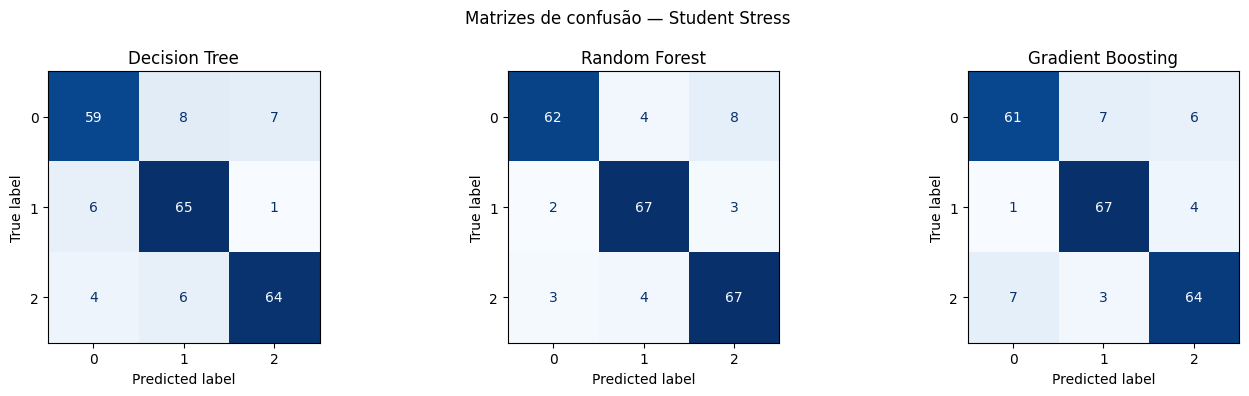

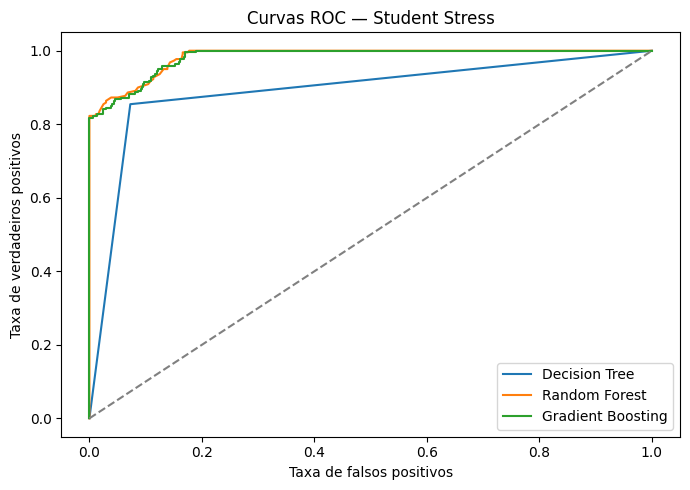

A curva desenhada é microagregada; o ROC_AUC da tabela é macro one-vs-rest.


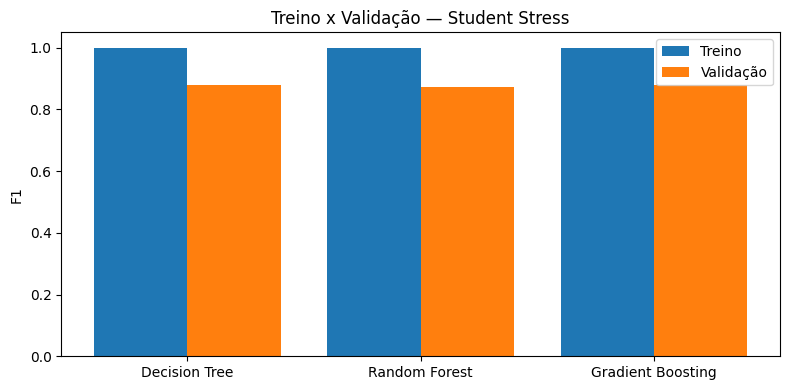

In [42]:
# Treino e comparação dos três modelos no dataset Student Stress.
executar_dataset('Student Stress')

### Dataset 2: Heart Disease

Heart Disease: cleaned_merged_heart_dataset.csv

Dataset: Heart Disease | Linhas/colunas no arquivo: (1888, 13)
Linhas com dados ausentes: 0


,age,sex,cp,trestbps,chol,fbs,restecg,thalachh,exang,oldpeak,slope,ca,thal
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2



Dataset: Heart Disease
Total: 602 | Treino (80%): 481 | Teste (20%): 121
Classes e quantidades: {0: 310, 1: 292}

Tabela comparativa:


,Dataset,Modelo,Acuracia,Precisao,F1,ROC_AUC,F1_CV,F1_Treino,Diferenca_Treino_CV
0,Heart Disease,Decision Tree,0.6446,0.6429,0.6261,0.6438,0.7092,1.0000,0.2908
1,Heart Disease,Random Forest,0.8099,0.8333,0.7965,0.9054,0.7827,1.0000,0.2173
2,Heart Disease,Gradient Boosting,0.8017,0.8182,0.7895,0.8794,0.7695,0.9374,0.1678



Melhor pela validação cruzada: Random Forest
F1 médio na CV: 0.7827
Análise: F1 de treino bem maior que o de validação. Pode ter overfitting (alta variância).
Obs.: esses critérios são apenas indícios, não uma comprovação da causa.


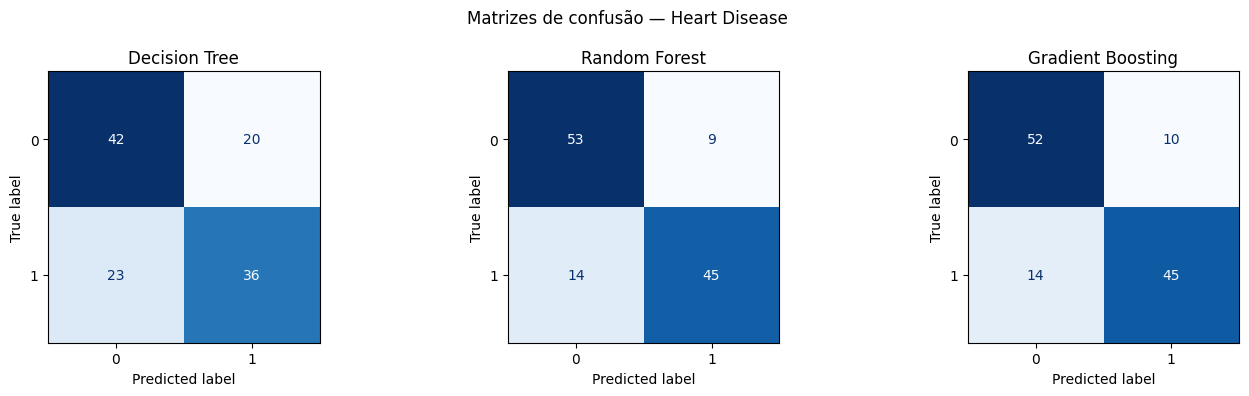

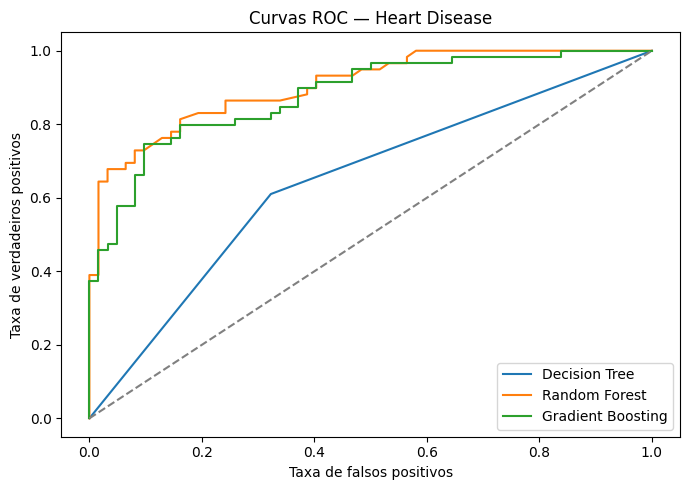

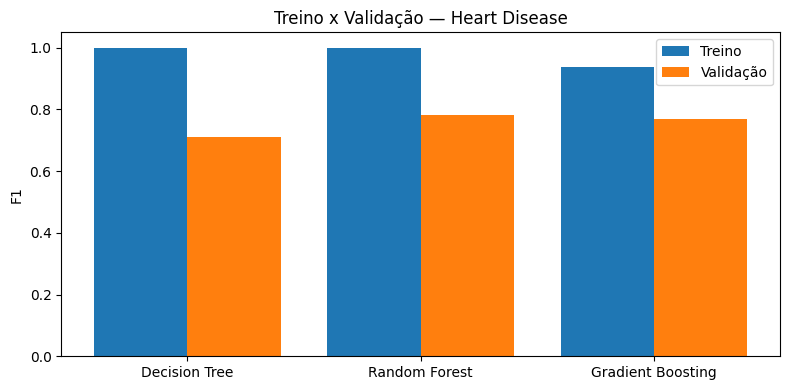

In [43]:
# Treino e comparação dos três modelos no dataset Heart Disease.
executar_dataset('Heart Disease')

### Dataset 3: FISHMORPH

Arquivo FISHMORPH: FISHMORPH_Database.csv

Dataset: FISHMORPH | Linhas/colunas no arquivo: (8342, 10)
Linhas com dados ausentes: 1951


,MBl,BEl,VEp,REs,OGp,RMl,BLs,PFv,PFs,CPt
0,130.0,4.579113,0.622642,0.375019,0.622642,0.868659,0.484981,0.273585,0.144108,3.348991
1,11.5,2.796068,0.650700,0.353780,0.509800,0.411157,0.722461,0.330169,0.221095,2.525592
2,6.6,4.564329,0.518187,0.312002,0.203985,0.413221,0.591495,0.105517,0.188193,2.104580
3,10.9,4.390422,0.548247,0.244804,0.168959,0.324728,0.642991,0.097450,0.193049,1.787062
4,18.9,4.410271,0.542353,0.292058,0.183790,0.398567,0.685672,0.087643,0.170648,2.968906



Dataset: FISHMORPH
Total: 6391 | Treino (80%): 5112 | Teste (20%): 1279
Classes e quantidades: {0: 4847, 1: 1544}

Tabela comparativa:


,Dataset,Modelo,Acuracia,Precisao,F1,ROC_AUC,F1_CV,F1_Treino,Diferenca_Treino_CV
0,FISHMORPH,Decision Tree,0.7803,0.5417,0.5643,0.7151,0.5687,1.0000,0.4313
1,FISHMORPH,Random Forest,0.8428,0.7308,0.6298,0.9181,0.6461,1.0000,0.3539
2,FISHMORPH,Gradient Boosting,0.8413,0.7137,0.6355,0.9057,0.6329,0.7338,0.1009



Melhor pela validação cruzada: Random Forest
F1 médio na CV: 0.6461
Análise: F1 de treino bem maior que o de validação. Pode ter overfitting (alta variância).
Obs.: esses critérios são apenas indícios, não uma comprovação da causa.


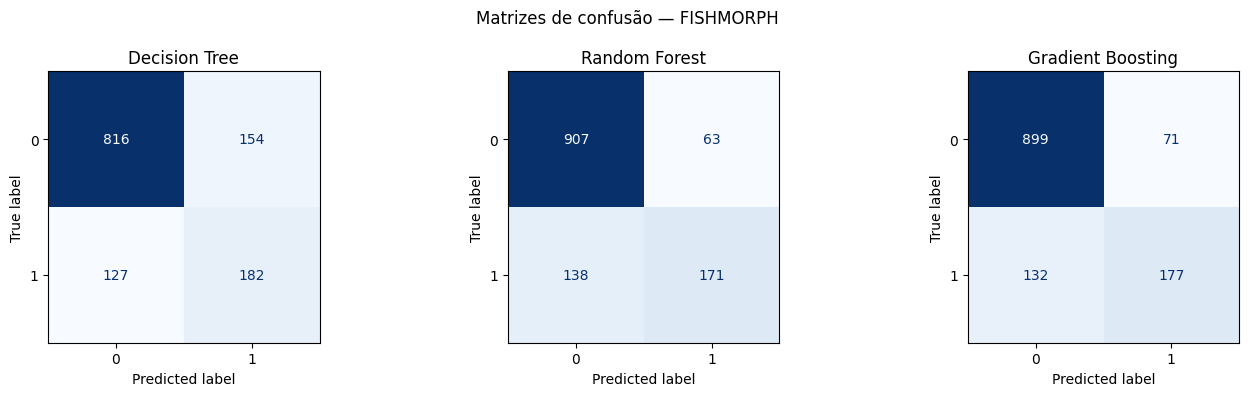

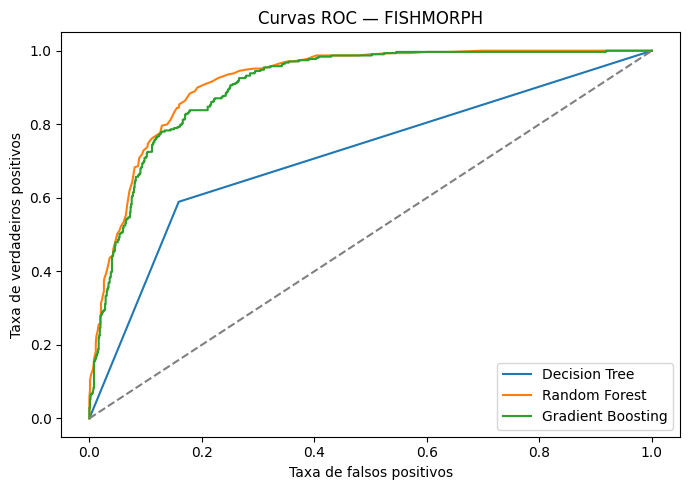

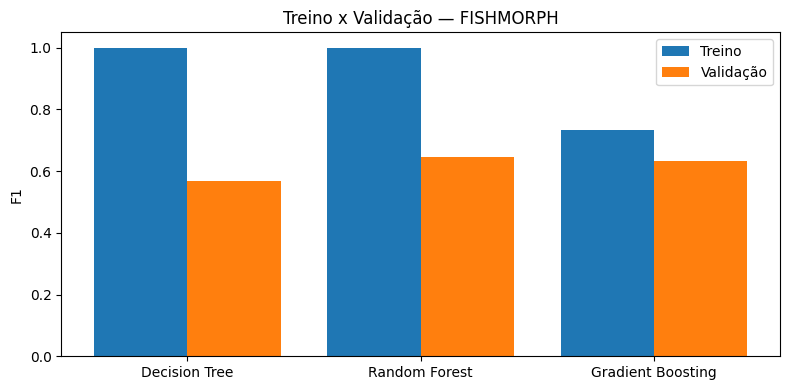

In [44]:
# Treino e comparação dos três modelos no dataset FISHMORPH.
executar_dataset('FISHMORPH')

### Dataset 4: Eleicao 1936


Dataset: Eleicao 1936 | Linhas/colunas no arquivo: (48, 3)
Linhas com dados ausentes: 0


,pesquisa_rep36,amostra_rep32,real_rep32
0,0.232841,0.138959,0.142940
1,0.541976,0.430088,0.312946
2,0.263647,0.170149,0.130541
3,0.536792,0.531941,0.390368
4,0.614037,0.571743,0.430464



Dataset: Eleicao 1936
Total: 48 | Treino (80%): 38 | Teste (20%): 10
Classes e quantidades: {0: 32, 1: 16}

Tabela comparativa:


,Dataset,Modelo,Acuracia,Precisao,F1,ROC_AUC,F1_CV,F1_Treino,Diferenca_Treino_CV
0,Eleicao 1936,Decision Tree,0.6,0.4286,0.60,0.7143,0.3410,1.0,0.6590
1,Eleicao 1936,Random Forest,0.8,0.6000,0.75,0.8571,0.6600,1.0,0.3400
2,Eleicao 1936,Gradient Boosting,0.6,0.4286,0.60,0.8095,0.4733,1.0,0.5267



Melhor pela validação cruzada: Random Forest
F1 médio na CV: 0.66
Análise: F1 de treino bem maior que o de validação. Pode ter overfitting (alta variância).
Obs.: esses critérios são apenas indícios, não uma comprovação da causa.


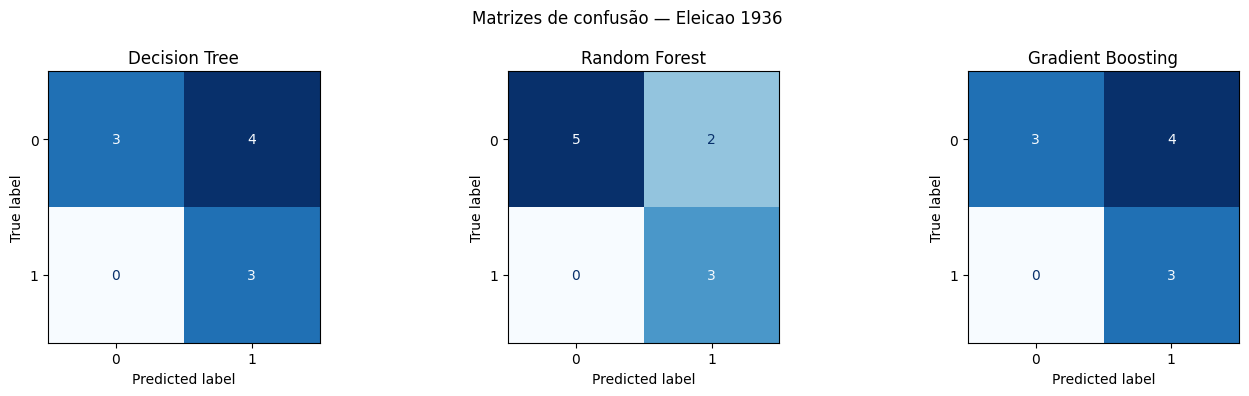

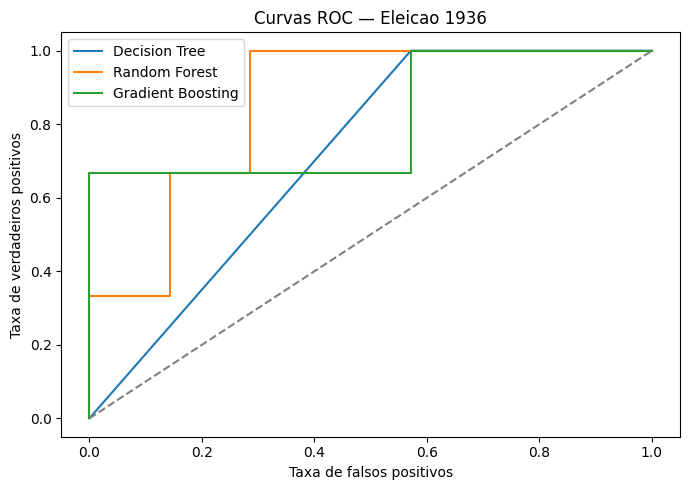

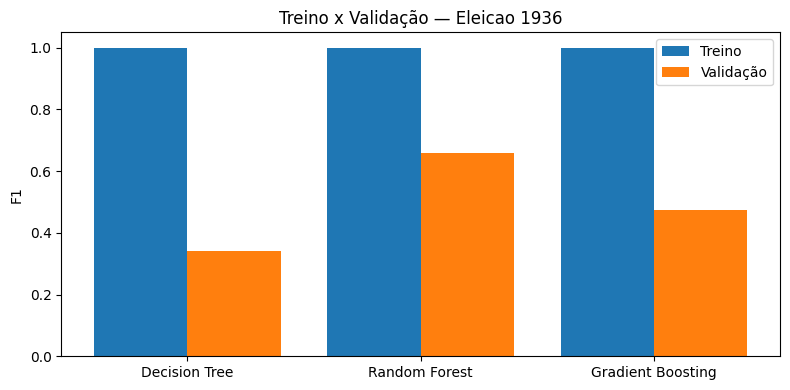

In [45]:
# Treino e comparação dos três modelos no dataset Eleicao 1936.
executar_dataset('Eleicao 1936')

### Dataset 5: Breast Cancer

Breast Cancer: data.csv

Dataset: Breast Cancer | Linhas/colunas no arquivo: (569, 30)
Linhas com dados ausentes: 0


,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Dataset: Breast Cancer
Total: 569 | Treino (80%): 455 | Teste (20%): 114
Classes e quantidades: {0: 357, 1: 212}

Tabela comparativa:


,Dataset,Modelo,Acuracia,Precisao,F1,ROC_AUC,F1_CV,F1_Treino,Diferenca_Treino_CV
0,Breast Cancer,Decision Tree,0.9298,0.9048,0.9048,0.9246,0.8962,1.0,0.1038
1,Breast Cancer,Random Forest,0.9737,1.0000,0.9630,0.9929,0.9519,1.0,0.0481
2,Breast Cancer,Gradient Boosting,0.9649,1.0000,0.9500,0.9947,0.9553,1.0,0.0447



Melhor pela validação cruzada: Gradient Boosting
F1 médio na CV: 0.9553
Análise: sem sinal muito forte de overfitting ou underfitting nesta comparação.
Obs.: esses critérios são apenas indícios, não uma comprovação da causa.


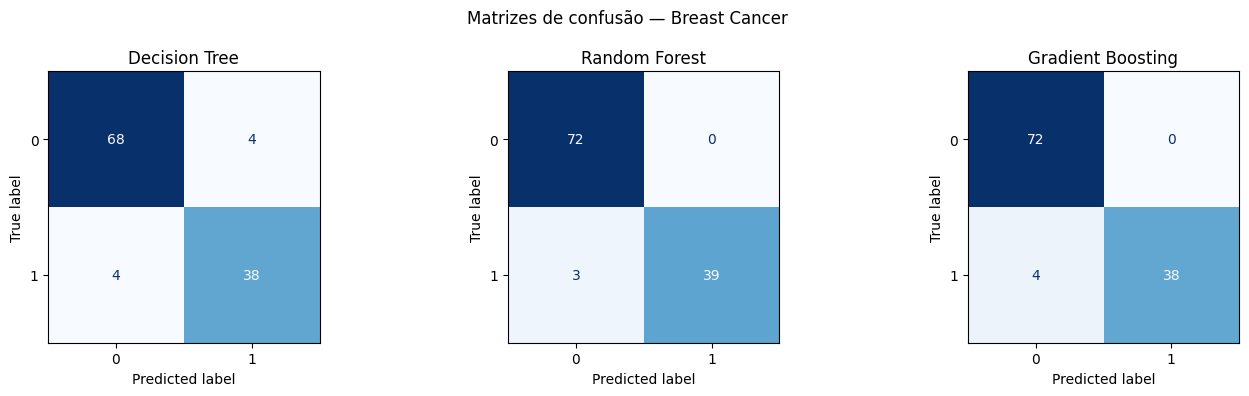

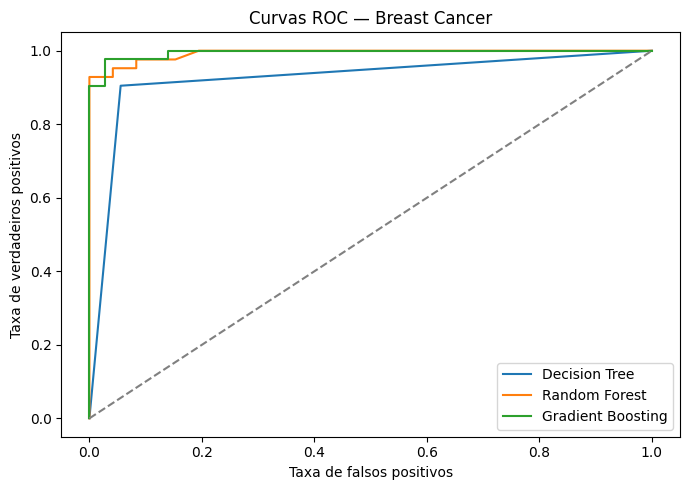

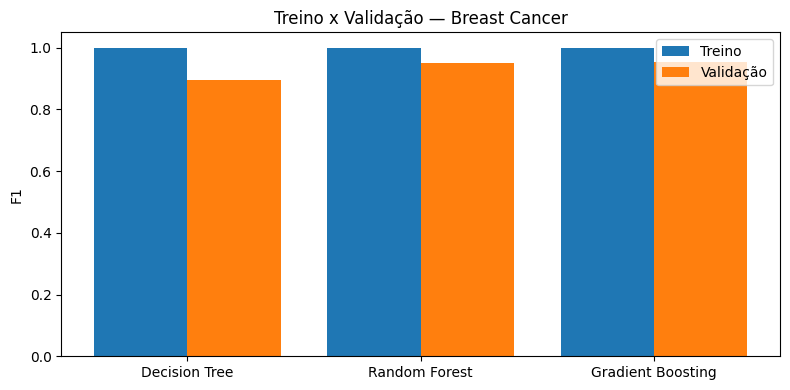

In [46]:
# Treino e comparação dos três modelos no dataset Breast Cancer.
executar_dataset('Breast Cancer')

### Dataset 6: Red Wine Quality

Red Wine Quality: winequality-red.csv

Dataset: Red Wine Quality | Linhas/colunas no arquivo: (1599, 11)
Linhas com dados ausentes: 0


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4



Dataset: Red Wine Quality
Total: 1359 | Treino (80%): 1087 | Teste (20%): 272
Classes e quantidades: {1: 719, 0: 640}

Tabela comparativa:


,Dataset,Modelo,Acuracia,Precisao,F1,ROC_AUC,F1_CV,F1_Treino,Diferenca_Treino_CV
0,Red Wine Quality,Decision Tree,0.625,0.6419,0.6507,0.6228,0.6920,1.0000,0.3080
1,Red Wine Quality,Random Forest,0.750,0.7794,0.7571,0.8370,0.7504,1.0000,0.2496
2,Red Wine Quality,Gradient Boosting,0.761,0.7801,0.7719,0.8275,0.7580,0.8737,0.1157



Melhor pela validação cruzada: Gradient Boosting
F1 médio na CV: 0.758
Análise: F1 de treino bem maior que o de validação. Pode ter overfitting (alta variância).
Obs.: esses critérios são apenas indícios, não uma comprovação da causa.


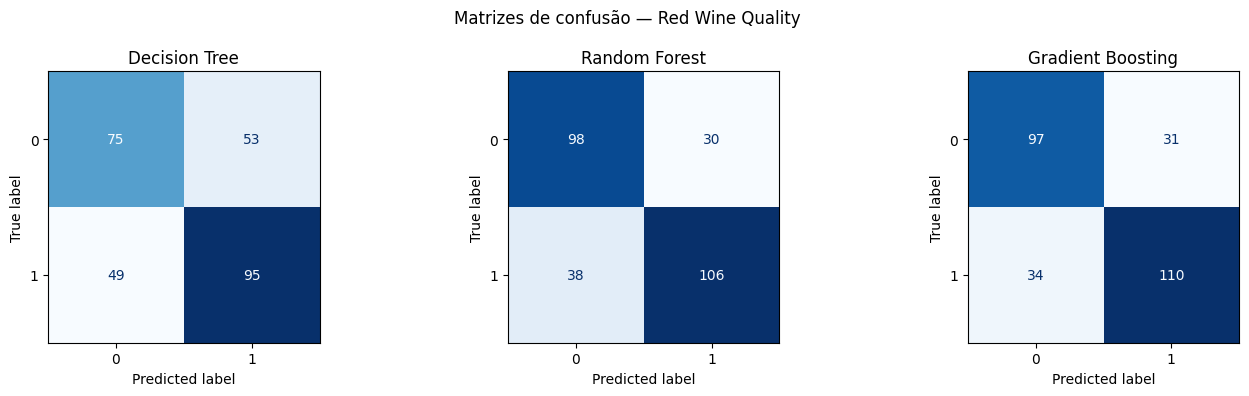

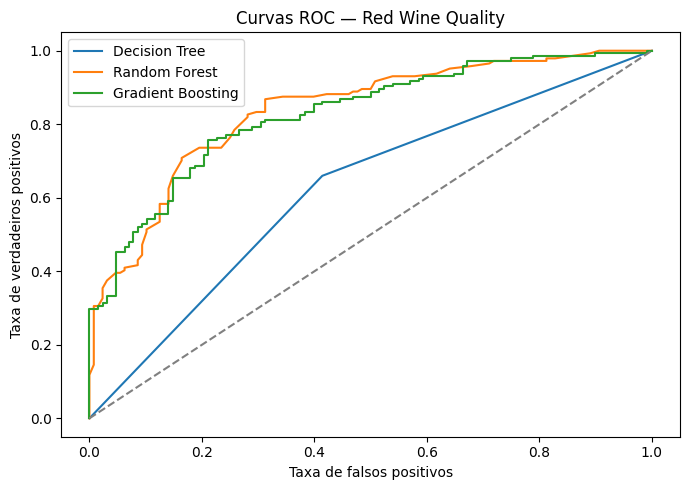

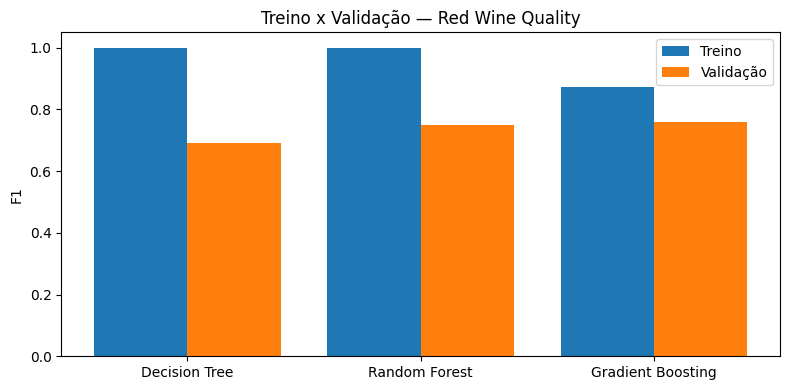

In [47]:
# Treino e comparação dos três modelos no dataset Red Wine Quality.
executar_dataset('Red Wine Quality')

## 7. Resumo dos resultados

As tabelas abaixo são preenchidas automaticamente, conforme o treinamento é executado. A primeira compara os **18 treinamentos**. A segunda informa o modelo de melhor F1 médio nos cinco folds de validação para cada dataset.

Lembrando: a validação escolhe o modelo usando apenas os 80% de treino. Os 20% de teste ficam reservados para a avaliação final.


In [48]:
resultados = pd.concat(todas_metricas, ignore_index=True)
print('Comparação geral dos 18 treinamentos:')
display(resultados)
resultados.to_csv(PASTA_RESULTADOS / 'resultados_gerais.csv', index=False)

print('\nMelhor modelo por dataset (pela validação cruzada):')
resumo = pd.DataFrame(melhores_modelos)
display(resumo)
resumo.to_csv(PASTA_RESULTADOS / 'melhores_modelos.csv', index=False)

print('Total de modelos treinados:', len(resultados))
assert len(resultados) == 18, 'A tabela deve ter seis datasets x três modelos = 18 linhas.'


Comparação geral dos 18 treinamentos:


,Dataset,Modelo,Acuracia,Precisao,F1,ROC_AUC,F1_CV,F1_Treino,Diferenca_Treino_CV
0,Student Stress,Decision Tree,0.8545,0.8556,0.8543,0.8912,0.8786,1.0000,0.1214
1,Student Stress,Random Forest,0.8909,0.8926,0.8909,0.9830,0.8717,1.0000,0.1283
2,Student Stress,Gradient Boosting,0.8727,0.8730,0.8724,0.9825,0.8806,1.0000,0.1194
3,Heart Disease,Decision Tree,0.6446,0.6429,0.6261,0.6438,0.7092,1.0000,0.2908
4,Heart Disease,Random Forest,0.8099,0.8333,0.7965,0.9054,0.7827,1.0000,0.2173
5,Heart Disease,Gradient Boosting,0.8017,0.8182,0.7895,0.8794,0.7695,0.9374,0.1678
6,FISHMORPH,Decision Tree,0.7803,0.5417,0.5643,0.7151,0.5687,1.0000,0.4313
7,FISHMORPH,Random Forest,0.8428,0.7308,0.6298,0.9181,0.6461,1.0000,0.3539
8,FISHMORPH,Gradient Boosting,0.8413,0.7137,0.6355,0.9057,0.6329,0.7338,0.1009
9,Eleicao 1936,Decision Tree,0.6000,0.4286,0.6000,0.7143,0.3410,1.0000,0.6590



Melhor modelo por dataset (pela validação cruzada):


,Dataset,Melhor modelo,F1 CV,F1 Teste
0,Student Stress,Gradient Boosting,0.8806,0.8724
1,Heart Disease,Random Forest,0.7827,0.7965
2,FISHMORPH,Random Forest,0.6461,0.6298
3,Eleicao 1936,Random Forest,0.6600,0.7500
4,Breast Cancer,Gradient Boosting,0.9553,0.9500
5,Red Wine Quality,Gradient Boosting,0.7580,0.7719


Total de modelos treinados: 18


Breast_Cancer_ROC.png


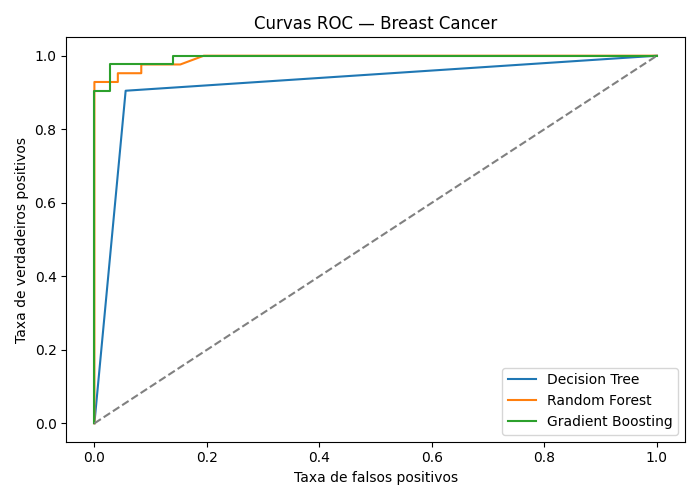

Breast_Cancer_comparacao.png


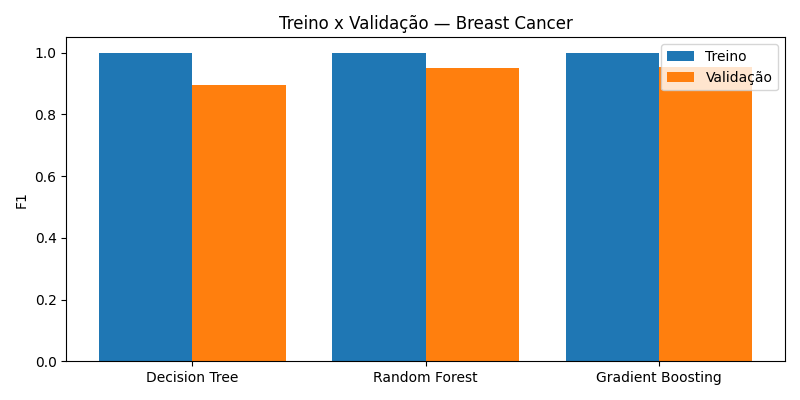

Breast_Cancer_confusao.png


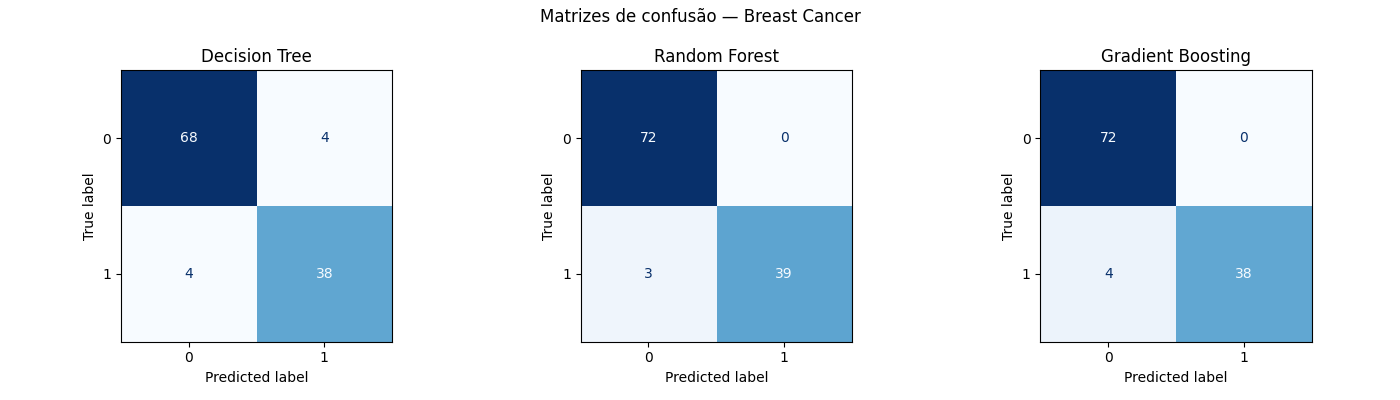

Eleicao_1936_ROC.png


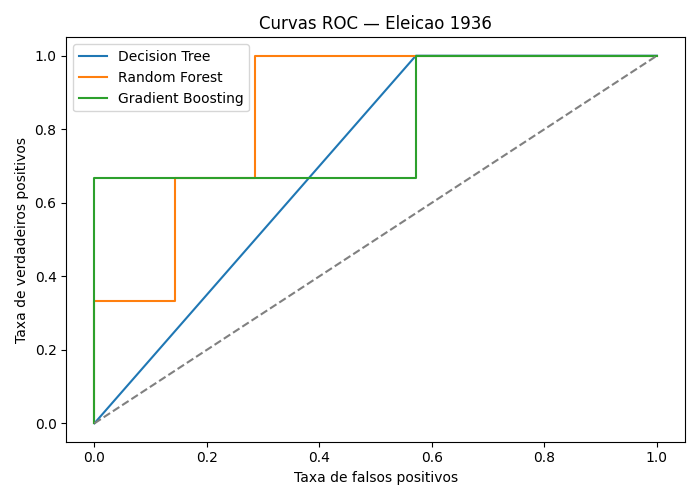

Eleicao_1936_comparacao.png


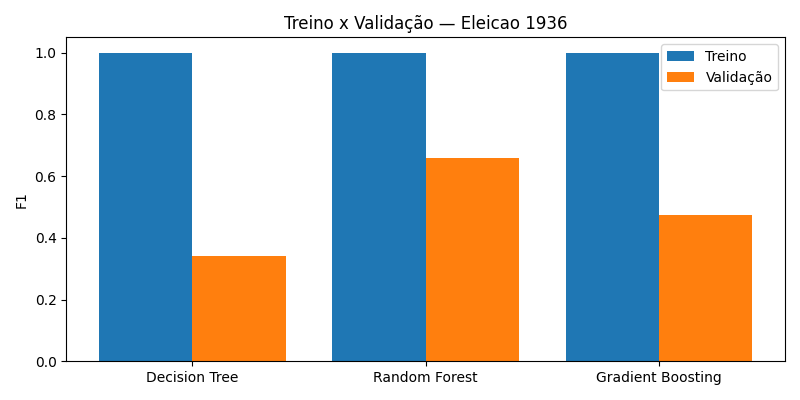

Eleicao_1936_confusao.png


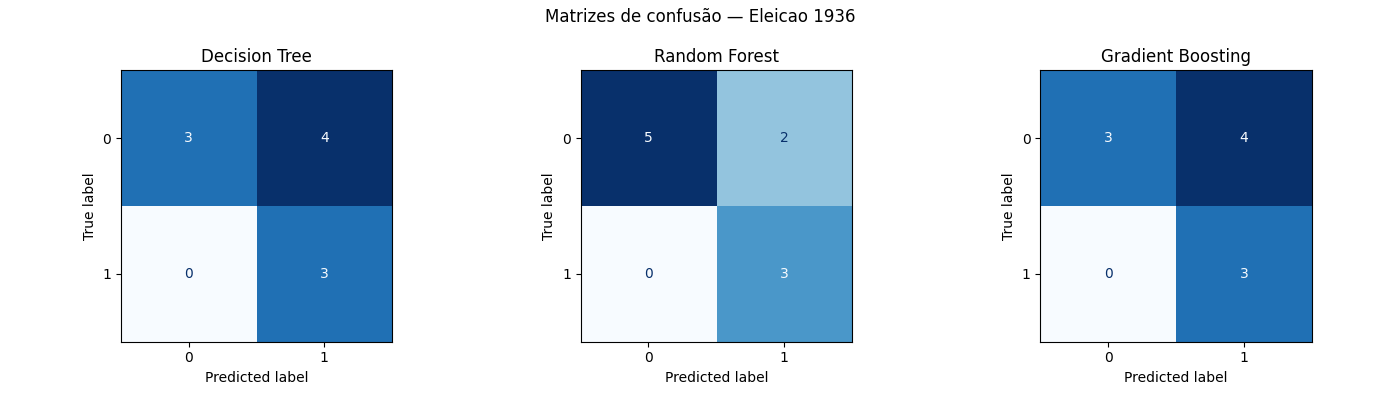

FISHMORPH_ROC.png


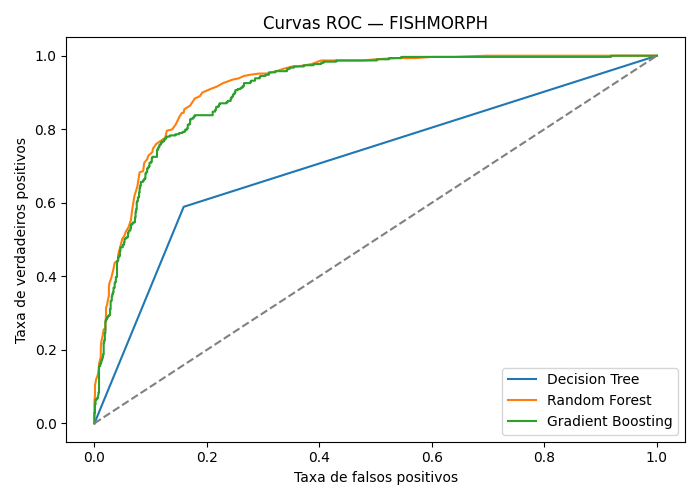

FISHMORPH_comparacao.png


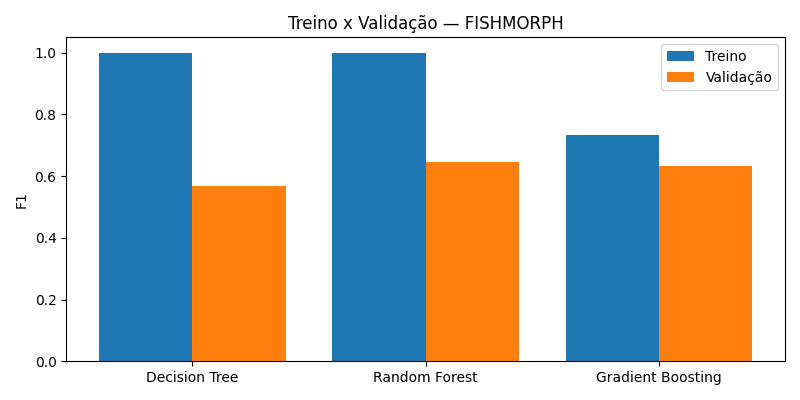

FISHMORPH_confusao.png


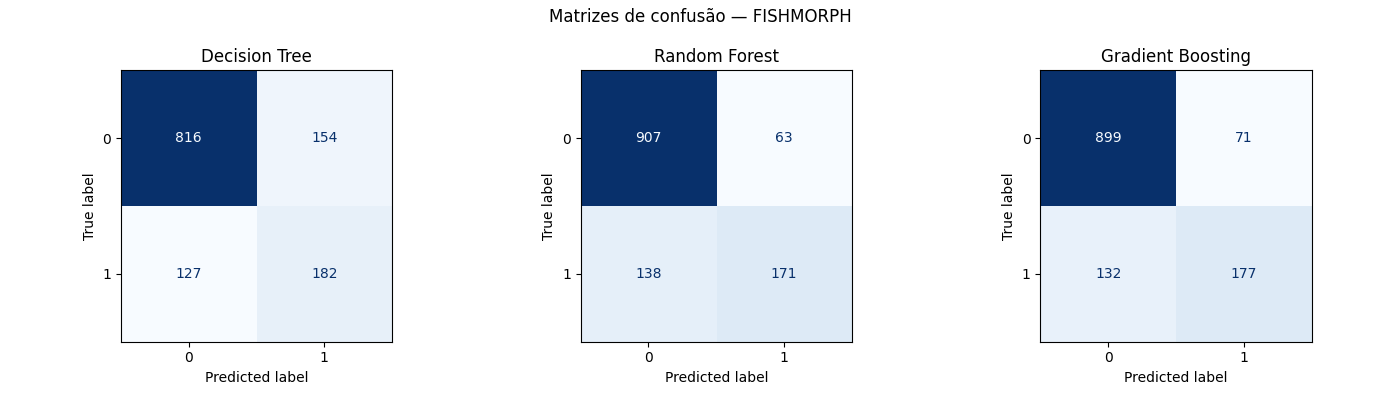

Heart_Disease_ROC.png


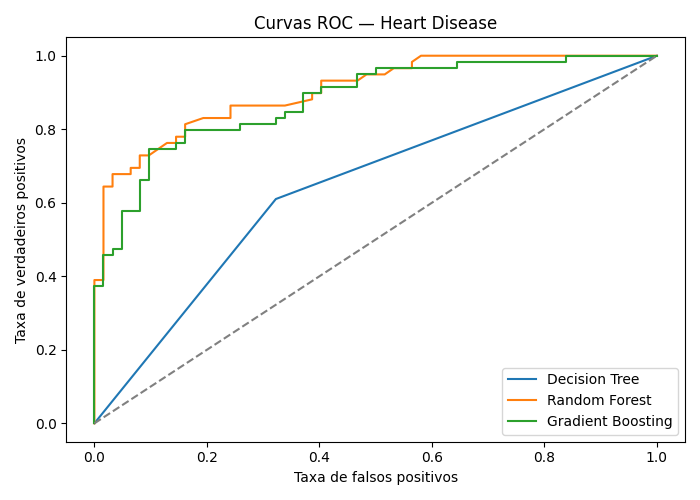

Heart_Disease_comparacao.png


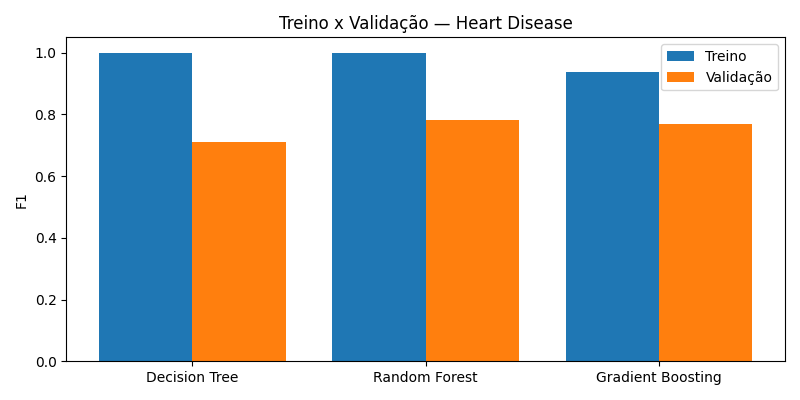

Heart_Disease_confusao.png


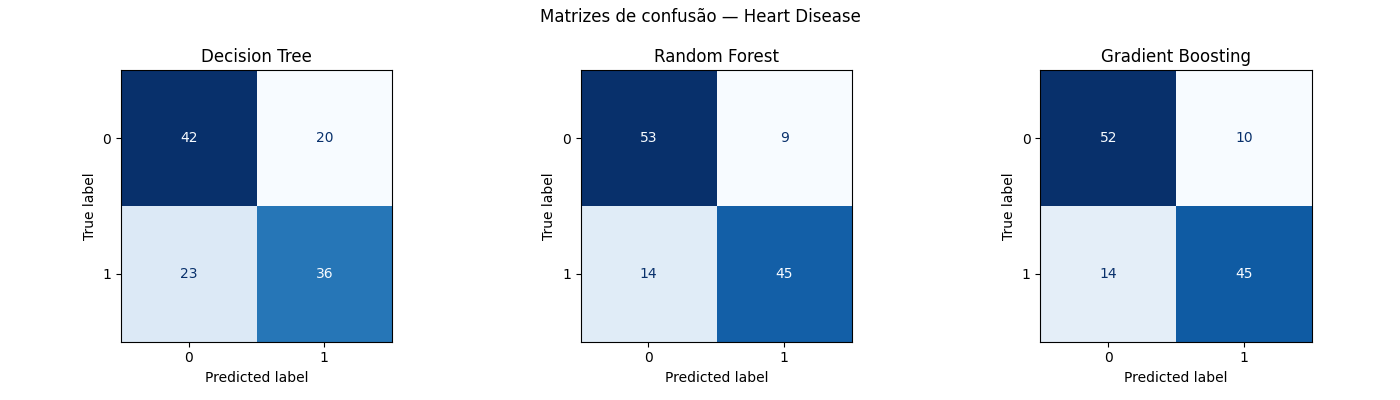

Red_Wine_Quality_ROC.png


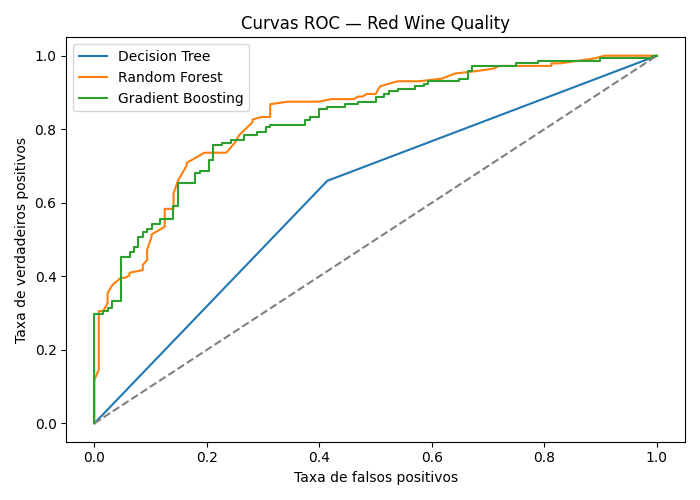

Red_Wine_Quality_comparacao.png


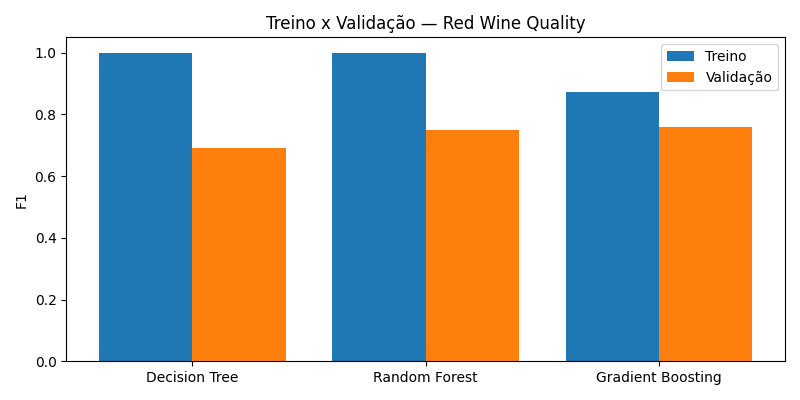

Red_Wine_Quality_confusao.png


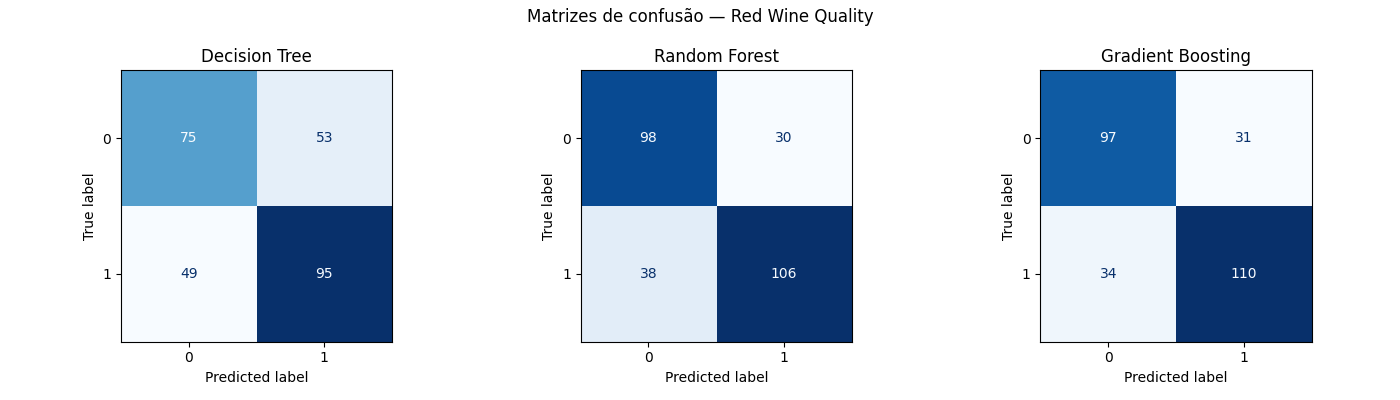

Student_Stress_ROC.png


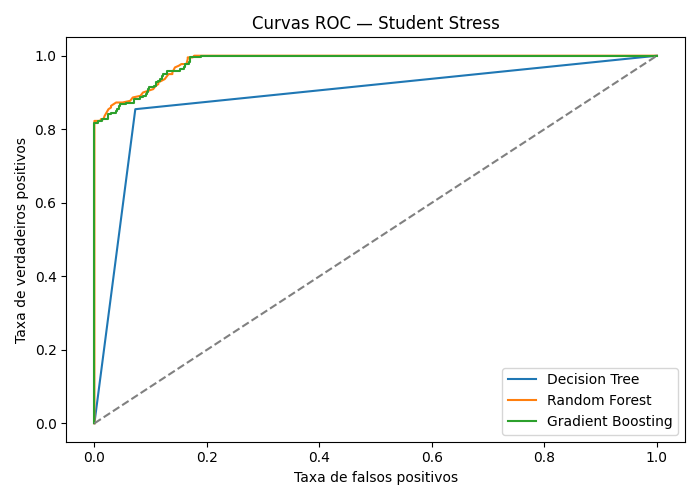

Student_Stress_comparacao.png


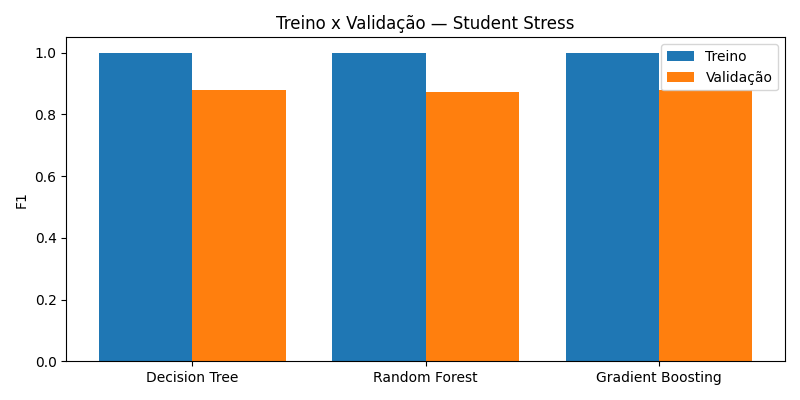

Student_Stress_confusao.png


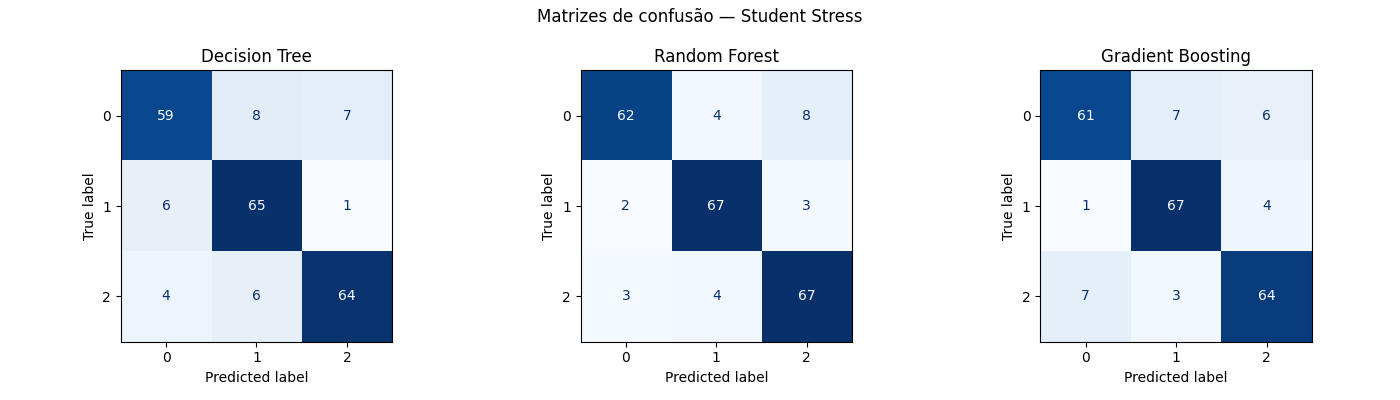

In [49]:
import os
from IPython.display import display, Image

# Procura e exibe todos os gráficos salvos
pasta = "resultados"

if os.path.exists(pasta):
    for arquivo in sorted(os.listdir(pasta)):
        if arquivo.endswith(".png"):
            print(arquivo)
            display(Image(filename=os.path.join(pasta, arquivo)))
else:
    print("Pasta de gráficos não encontrada")


## 8. Conclusão e como entender os resultados

- **Acurácia:** proporção de respostas corretas.
- **Precisão:** entre os casos previstos como positivos, quantos estavam certos; no Student Stress, é a média das três classes.
- **F1:** combina precisão e recall, por isso é usado para comparar os modelos.
- **ROC/AUC:** avalia a capacidade de separar as classes usando as probabilidades previstas. No Student Stress há três classes, então a tabela mostra AUC macro (um contra os demais), e a figura representa uma curva agregada.
- **Matriz de confusão:** mostra os acertos na diagonal e os erros fora dela. Nos problemas binários, ajuda a observar falsos positivos e falsos negativos.
- **Possível overfitting:** quando o F1 de treino fica muito acima do F1 da validação, o modelo pode estar decorando os dados.
- **Possível underfitting:** quando os resultados de treino e validação são baixos, o modelo pode não estar aprendendo bem o padrão.

O modelo destacado em cada dataset foi escolhido pelo **maior F1 médio na validação cruzada**. Ganhar com Random Forest não prova automaticamente que o problema era alta variância; ganhar com Gradient Boosting também não prova, sozinho, que havia alto viés. É necessário observar as diferenças de treino e validação.

Esta comparação é apenas um exercício de classificação. Os modelos não devem ser usados para tomar decisões médicas nem prever resultados eleitorais futuros.
